# 04. Сравнение обогащения текстовых данных

Две модели — TF-IDF с логистической регрессией и CatBoost — обучаются на четырёх вариантах: исходные данные UCI; исходные и 112 дополнительных отзывов; исходные и синтетические; исходные, дополнительные и синтетические. Для всех запусков используются одни и те же исходные validation и test.

**Как запускать:** подключите Colab runtime через расширение VS Code, выберите CPU и выполняйте ячейки по порядку. При подключении Drive дайте доступ своему аккаунту. Если папка проекта находится в «Доступные мне», добавьте её ярлык в «Мой диск» или укажите путь к доступной папке в следующей ячейке настройки.

Нужны файлы `processed/text/reviews_clean.csv`, `splits/text/uci_split_seed42.csv` и `.json`, `manual/text/manual_text_agreed_112.json`, `augmented/text/draft_codex.json` относительно папки проекта на Drive. Результаты и модели сохраняются в новую папку `results/text/training/` на Drive; существующие запуски не перезаписываются.

In [1]:
# При необходимости установите зависимости в подключённую среду Colab.
import importlib.util
import subprocess
import sys

needed = []
for module, package in [('catboost', 'catboost>=1.2.8,<2'), ('sklearn', 'scikit-learn>=1.4,<2'),
                        ('matplotlib', 'matplotlib>=3.8,<4'), ('pandas', 'pandas>=2.2,<3')]:
    if importlib.util.find_spec(module) is None:
        needed.append(package)
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *needed])
    importlib.invalidate_caches()
print('Зависимости доступны в текущем окружении.')


Зависимости доступны в текущем окружении.


## 1. Google Drive и параметры

По умолчанию используются все 3 000 синтетических отзывов. Для сравнения равных объёмов выберите `matched`: будет выбрано 112 синтетических отзывов с тем же числом положительных и отрицательных меток, что и в ручном наборе. Это отдельный повторный запуск, а не автоматический выбор лучшего результата по test.


In [2]:
from pathlib import Path
import os
import uuid
from datetime import datetime, timezone

# 'all' — все 3000 синтетических отзывов; 'matched' — 112.
SYNTHETIC_MODE = 'all'
SEED = 42
if SYNTHETIC_MODE not in {'all', 'matched'}:
    raise ValueError("SYNTHETIC_MODE должен быть 'all' или 'matched'.")

# Переменная окружения позволяет проверить ноутбук локально; в Colab используется Drive.
local_root = os.environ.get('COURSEWORK_DATA_ROOT')
if local_root:
    ROOT = Path(local_root).expanduser().resolve()
else:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Выберите подключённую среду Colab в VS Code и повторите запуск.') from exc
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/data-enrichment-coursework')

# Измените ROOT здесь, если папка проекта расположена в другом месте Google Drive.
PATHS = {
    'uci': ROOT / 'processed/text/reviews_clean.csv',
    'split': ROOT / 'splits/text/uci_split_seed42.csv',
    'split_meta': ROOT / 'splits/text/uci_split_seed42.json',
    'manual': ROOT / 'manual/text/manual_text_agreed_112.json',
    'synthetic': ROOT / 'augmented/text/draft_codex.json',
}
missing = [str(p) for p in PATHS.values() if not p.is_file()]
if missing:
    raise FileNotFoundError('Не найдены файлы:\n' + '\n'.join(missing) +
                            '\nПроверьте ROOT, наличие файлов и ярлык общей папки в «Мой диск».')
print('Папка проекта:', ROOT)
for name, path in PATHS.items():
    print(name, '→', path)


Mounted at /content/drive
Папка проекта: /content/drive/MyDrive/data-enrichment-coursework
uci → /content/drive/MyDrive/data-enrichment-coursework/processed/text/reviews_clean.csv
split → /content/drive/MyDrive/data-enrichment-coursework/splits/text/uci_split_seed42.csv
split_meta → /content/drive/MyDrive/data-enrichment-coursework/splits/text/uci_split_seed42.json
manual → /content/drive/MyDrive/data-enrichment-coursework/manual/text/manual_text_agreed_112.json
synthetic → /content/drive/MyDrive/data-enrichment-coursework/augmented/text/draft_codex.json


## 2. Загрузка и проверка разбиения

Сопоставляем ID, метки и источники с зафиксированным разбиением и проверяем SHA-256 исходной таблицы. После нормализации регистра и пунктуации два текста train совпадают с test: они исключаются **только из train каждого варианта**. Validation и test не изменяются. Проверка не гарантирует отсутствия смысловых перефразирований.


In [3]:
import hashlib
import json
import re
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import catboost
from catboost import CatBoostClassifier
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             balanced_accuracy_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import joblib
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)


def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def normalized_text(value):
    return ' '.join(re.findall(r'\w+', str(value).casefold()))


def prepare(frame, name, expected_count):
    required = {'id', 'text', 'label', 'source'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{name}: отсутствуют поля {sorted(required - set(frame.columns))}')
    frame = frame.copy()
    if len(frame) != expected_count or frame['id'].isna().any() or frame['id'].duplicated().any():
        raise ValueError(f'{name}: неверное число строк или повторяющиеся / пустые ID.')
    if frame['text'].isna().any() or frame['source'].isna().any():
        raise ValueError(f'{name}: отсутствует текст или источник.')
    frame['text'] = frame['text'].astype(str)
    frame['norm'] = frame['text'].map(normalized_text)
    if frame['norm'].eq('').any():
        raise ValueError(f'{name}: есть пустой текст.')
    labels = pd.to_numeric(frame['label'], errors='raise')
    if labels.isna().any() or not labels.isin([0, 1]).all():
        raise ValueError(f'{name}: метки должны быть 0 или 1.')
    frame['label'] = labels.astype(int)
    return frame

uci = prepare(pd.read_csv(PATHS['uci']), 'UCI', 2979)
manual = prepare(pd.read_json(PATHS['manual']), 'Ручные отзывы', 112)
synthetic = prepare(pd.read_json(PATHS['synthetic']), 'Синтетические отзывы', 3000)
split = pd.read_csv(PATHS['split'], dtype={'id': str})
meta = json.loads(PATHS['split_meta'].read_text(encoding='utf-8'))
if sha256_file(PATHS['uci']) != meta['input_sha256'] or sha256_file(PATHS['split']) != meta['split_file_sha256']:
    raise ValueError('Хеш UCI или разбиения отличается от сохранённого. Проверьте версии файлов на Drive.')
if not {'id', 'source', 'label', 'split'}.issubset(split.columns) or split['id'].isna().any() or split['id'].duplicated().any():
    raise ValueError('Файл разбиения должен содержать уникальные ID, source, label и split.')
if len(split) != len(uci) or set(split['id']) != set(uci['id']):
    raise ValueError('ID в разбиении и в очищенном UCI не совпадают.')
if set(split['split']) != {'train', 'validation', 'test'}:
    raise ValueError('В разбиении должны быть train, validation и test.')
joined = uci.merge(split, on='id', validate='one_to_one', suffixes=('', '_split'))
if not (joined['source'] == joined['source_split']).all() or not (joined['label'] == pd.to_numeric(joined['label_split'])).all():
    raise ValueError('Метки или источники в разбиении не совпадают с UCI.')
train = joined.loc[joined['split'].eq('train')].copy()
val = joined.loc[joined['split'].eq('validation')].copy()
test = joined.loc[joined['split'].eq('test')].copy()
if set(val['norm']) & set(test['norm']):
    raise ValueError('Найдены совпадения между validation и test после нормализации. Разбиение требует проверки.')
heldout = set(val['norm']) | set(test['norm'])
excluded_train = train.loc[train['norm'].isin(heldout), ['id', 'text', 'label', 'source']].copy()
train = train.loc[~train['norm'].isin(heldout)].copy()
for name, frame in [('manual', manual), ('synthetic', synthetic)]:
    if frame['norm'].duplicated().any():
        raise ValueError(f'{name}: найдены повторы после нормализации.')
    if set(frame['norm']) & heldout:
        raise ValueError(f'{name}: есть точное совпадение с validation/test после нормализации.')
    if set(frame['norm']) & set(train['norm']):
        raise ValueError(f'{name}: есть совпадение с исходным train после нормализации.')
if set(manual['norm']) & set(synthetic['norm']):
    raise ValueError('Между ручными и синтетическими отзывами найдены совпадения.')
if len(set(train['id']) | set(manual['id']) | set(synthetic['id'])) != len(train) + len(manual) + len(synthetic):
    raise ValueError('ID в исходных и дополнительных данных пересекаются.')
print('Исключено из train из-за совпадений с validation/test:', len(excluded_train))
display(excluded_train)
print('UCI: train', len(train), ', validation', len(val), ', test', len(test))
print('Дополнения: manual', len(manual), ', synthetic', len(synthetic))


Исключено из train из-за совпадений с validation/test: 2


,id,text,label,source
980,amazon_0994,disappointed.,0,amazon
1608,yelp_0622,Very disappointing!!!,0,yelp


UCI: train 2379 , validation 299 , test 299
Дополнения: manual 112 , synthetic 3000


## 3. Четыре варианта обучения

У всех вариантов одна исходная обучающая часть. Ручные и синтетические отзывы не добавляются в validation/test. Колонка `source` используется для учёта и отчёта, но **не передаётся** модели в качестве признака. В режиме `matched` выборка синтетических отзывов одинакова для обоих вариантов, где она используется.


In [4]:
if SYNTHETIC_MODE == 'matched':
    desired = manual['label'].value_counts().to_dict()
    parts = []
    for label in sorted(desired):
        candidates = synthetic.loc[synthetic['label'].eq(label)].sort_values('id')
        if len(candidates) < desired[label]:
            raise ValueError(f'Недостаточно синтетических отзывов класса {label}.')
        parts.append(candidates.sample(n=desired[label], random_state=SEED + int(label)))
    selected_synthetic = pd.concat(parts, ignore_index=True)
else:
    selected_synthetic = synthetic.copy()

columns = ['id', 'text', 'label', 'source', 'norm']
def combine(*frames):
    result = pd.concat([frame[columns] for frame in frames], ignore_index=True)
    if result['id'].duplicated().any():
        raise ValueError('В тренировочном варианте найдены повторяющиеся ID.')
    if set(result['norm']) & heldout:
        raise ValueError('Тренировочный вариант пересекается с validation/test.')
    return result

variants = {
    'baseline': combine(train),
    'manual': combine(train, manual),
    'synthetic': combine(train, selected_synthetic),
    'manual_synthetic': combine(train, manual, selected_synthetic),
}
variant_labels = {'baseline': 'Исходные', 'manual': 'Исходные + ручные',
                  'synthetic': 'Исходные + синтетические', 'manual_synthetic': 'Исходные + ручные + синтетические'}
display(pd.DataFrame([{'variant': key, 'описание': variant_labels[key], 'n_train': len(frame),
                       'negative': int((frame.label == 0).sum()), 'positive': int((frame.label == 1).sum())}
                      for key, frame in variants.items()]))


,variant,описание,n_train,negative,positive
0,baseline,Исходные,2379,1189,1190
1,manual,Исходные + ручные,2491,1246,1245
2,synthetic,Исходные + синтетические,5379,2689,2690
3,manual_synthetic,Исходные + ручные + синтетические,5491,2746,2745


## 4. Обучение двух моделей

Для каждого варианта заново обучается весь конвейер: TF-IDF и логистическая регрессия либо CatBoost с текстовым признаком. Настройки внутри каждой модели одинаковы во всех четырёх запусках. Источник данных в модель не передаётся. Для честного сравнения число итераций CatBoost фиксировано: test и validation не участвуют в остановке обучения.


In [5]:
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
RUN_DIR = ROOT / 'results/text/training' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
models_dir = RUN_DIR / 'models'
models_dir.mkdir()
excluded_train.to_csv(RUN_DIR / 'excluded_train_overlap.csv', index=False)
selected_synthetic[['id', 'label', 'source']].to_csv(RUN_DIR / 'selected_synthetic_ids.csv', index=False)

model_config = {
    'LogisticRegression': {'tfidf': {'ngram_range': [1, 2], 'min_df': 1},
                           'logistic': {'C': 1.0, 'max_iter': 1000, 'random_state': SEED}},
    'CatBoost': {'iterations': 500, 'depth': 6, 'learning_rate': 0.1,
                 'loss_function': 'Logloss', 'random_seed': SEED,
                 'thread_count': 4, 'task_type': 'CPU', 'allow_writing_files': False},
}
models = {}
for variant_name, frame in variants.items():
    print('Обучение:', variant_labels[variant_name], '—', len(frame), 'отзывов')
    logistic = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=1),
                             LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))
    logistic.fit(frame['text'], frame['label'])
    models[('LogisticRegression', variant_name)] = logistic
    joblib.dump(logistic, models_dir / f'logistic_{variant_name}.joblib')

    booster = CatBoostClassifier(**model_config['CatBoost'], verbose=False)
    booster.fit(frame[['text']], frame['label'], text_features=['text'])
    models[('CatBoost', variant_name)] = booster
    booster.save_model(str(models_dir / f'catboost_{variant_name}.cbm'))
print('Все модели обучены. Результаты сохраняются в:', RUN_DIR)


Обучение: Исходные — 2379 отзывов
Обучение: Исходные + ручные — 2491 отзывов
Обучение: Исходные + синтетические — 5379 отзывов
Обучение: Исходные + ручные + синтетические — 5491 отзывов
Все модели обучены. Результаты сохраняются в: /content/drive/MyDrive/data-enrichment-coursework/results/text/training/20261117T191709Z_0d765b78


## 5. Метрики и сравнение на едином test

Основная метрика — **F1-macro**: среднее F1 для отрицательного и положительного классов. Также приводятся macro precision/recall, accuracy, balanced accuracy и ROC-AUC. Изменение F1 показано относительно базовой модели того же типа. Test не используется для выбора параметров; после просмотра его результатов не следует подбирать настройки по этой же выборке.


In [6]:
def evaluate(model_name, model, frame):
    X = frame['text'] if model_name == 'LogisticRegression' else frame[['text']]
    probability = np.asarray(model.predict_proba(X))[:, 1]
    predictions = (probability >= 0.5).astype(int)
    truth = frame['label'].to_numpy()
    precision, recall, f1, _ = precision_recall_fscore_support(truth, predictions, average='macro', zero_division=0)
    scores = {'accuracy': accuracy_score(truth, predictions), 'precision_macro': precision,
              'recall_macro': recall, 'f1_macro': f1,
              'balanced_accuracy': balanced_accuracy_score(truth, predictions),
              'roc_auc': roc_auc_score(truth, probability)}
    return scores, predictions, probability

rows = []
all_predictions = []
reports = {}
for partition_name, frame in [('validation', val), ('test', test)]:
    for (model_name, variant_name), model in models.items():
        scores, pred, prob = evaluate(model_name, model, frame)
        rows.append({'partition': partition_name, 'model': model_name, 'variant': variant_name,
                     'n_train': len(variants[variant_name]), 'n_eval': len(frame), **scores})
        reports[f'{partition_name}/{model_name}/{variant_name}'] = classification_report(
            frame['label'], pred, labels=[0, 1], target_names=['negative', 'positive'], output_dict=True, zero_division=0)
        predictions = frame[['id', 'source', 'label']].copy().reset_index(drop=True)
        predictions['partition'] = partition_name
        predictions['model'] = model_name
        predictions['variant'] = variant_name
        predictions['prediction'] = pred
        predictions['probability_positive'] = prob
        all_predictions.append(predictions)

metrics = pd.DataFrame(rows)
predictions_table = pd.concat(all_predictions, ignore_index=True)
results_table = metrics.loc[metrics['partition'].eq('test')].copy()
baselines = results_table.loc[results_table['variant'].eq('baseline')].set_index('model')['f1_macro']
results_table['delta_f1_vs_baseline'] = results_table['f1_macro'] - results_table['model'].map(baselines)
results_table['variant_name'] = results_table['variant'].map(variant_labels)
order = {'baseline': 0, 'manual': 1, 'synthetic': 2, 'manual_synthetic': 3}
results_table['_order'] = results_table['variant'].map(order)
results_table = results_table.sort_values(['model', '_order']).drop(columns='_order').reset_index(drop=True)
print('Итоговое сравнение на test:')
display(results_table[['model', 'variant_name', 'n_train', 'accuracy', 'precision_macro', 'recall_macro',
                       'f1_macro', 'delta_f1_vs_baseline', 'balanced_accuracy', 'roc_auc']].round(4))
print('Положительная разница F1 означает улучшение относительно базовой модели того же типа.')


Итоговое сравнение на test:


,model,variant_name,n_train,accuracy,precision_macro,recall_macro,f1_macro,delta_f1_vs_baseline,balanced_accuracy,roc_auc
0,CatBoost,Исходные,2379,0.7291,0.7328,0.7289,0.7279,0.0000,0.7289,0.8150
1,CatBoost,Исходные + ручные,2491,0.7324,0.7351,0.7323,0.7316,0.0037,0.7323,0.8138
2,CatBoost,Исходные + синтетические,5379,0.7023,0.7114,0.7020,0.6989,-0.0290,0.7020,0.7923
3,CatBoost,Исходные + ручные + синтетические,5491,0.7057,0.7183,0.7053,0.7011,-0.0268,0.7053,0.7942
4,LogisticRegression,Исходные,2379,0.7993,0.7993,0.7993,0.7993,0.0000,0.7993,0.8820
5,LogisticRegression,Исходные + ручные,2491,0.7960,0.7961,0.7960,0.7960,-0.0034,0.7960,0.8858
6,LogisticRegression,Исходные + синтетические,5379,0.7793,0.7797,0.7792,0.7791,-0.0202,0.7792,0.8595
7,LogisticRegression,Исходные + ручные + синтетические,5491,0.7826,0.7829,0.7826,0.7825,-0.0168,0.7826,0.8600


Положительная разница F1 означает улучшение относительно базовой модели того же типа.


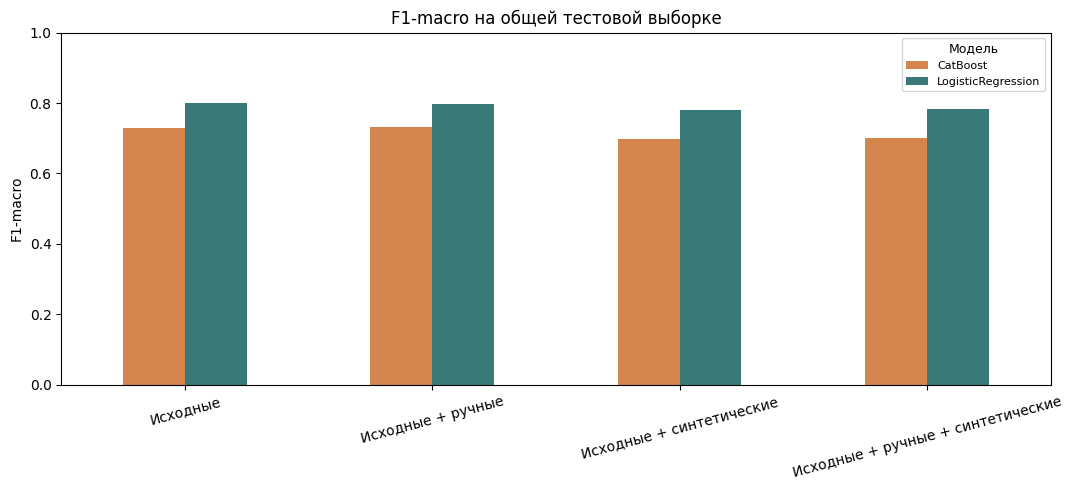

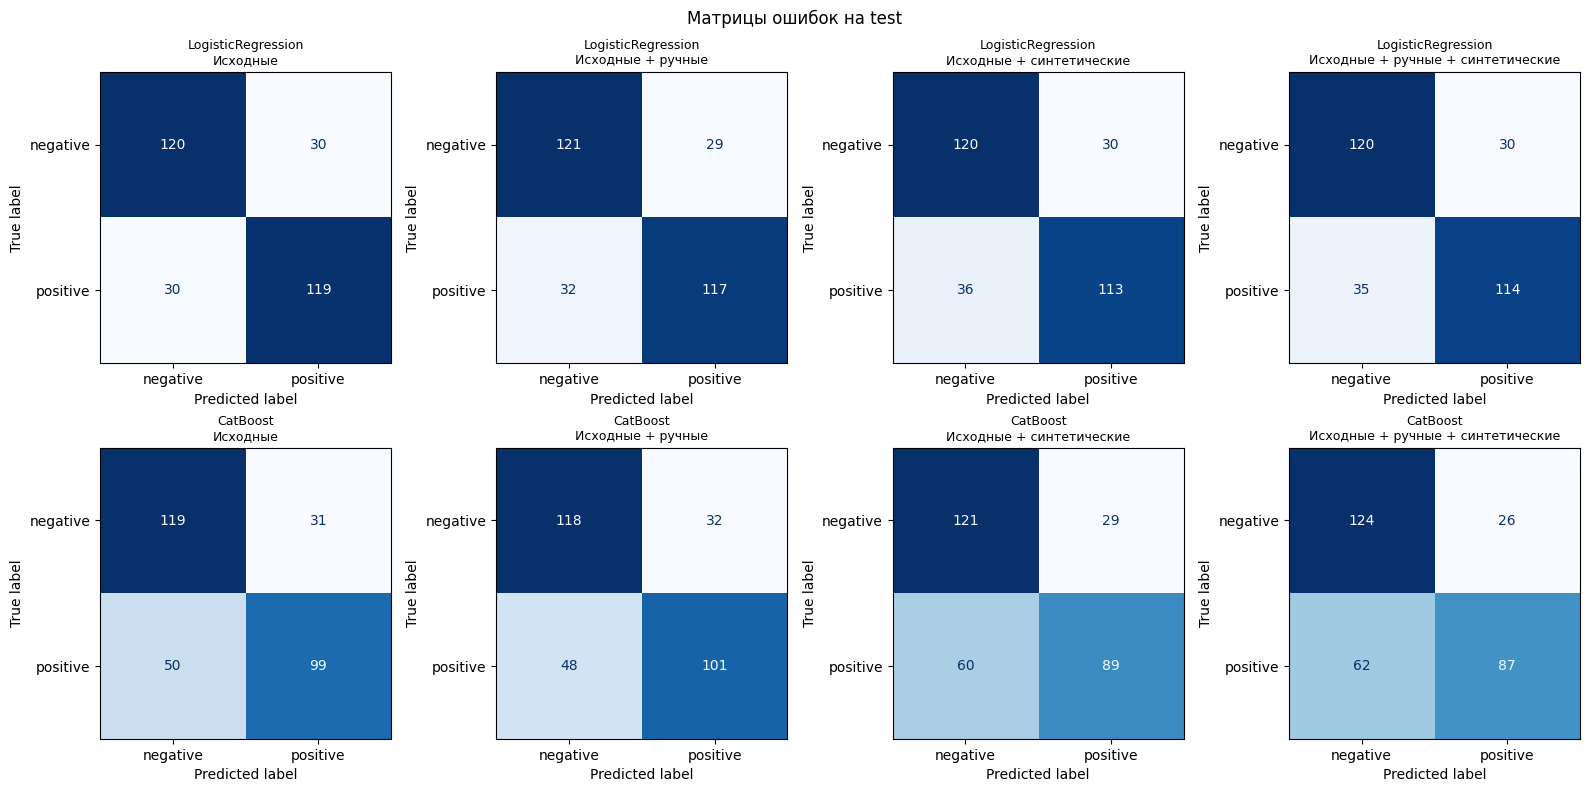

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_data = results_table.pivot(index='variant_name', columns='model', values='f1_macro').reindex(
    [variant_labels[k] for k in variants])
plot_data.plot(kind='bar', ax=ax, color=['#d3854c', '#397a78'])
ax.set(title='F1-macro на общей тестовой выборке', xlabel='', ylabel='F1-macro', ylim=(0, 1))
ax.legend(title='Модель', fontsize=8, title_fontsize=9)
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig(RUN_DIR / 'test_f1_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row_index, model_name in enumerate(['LogisticRegression', 'CatBoost']):
    for col_index, variant_name in enumerate(variants):
        subset = predictions_table.query('partition == "test" and model == @model_name and variant == @variant_name')
        cm = confusion_matrix(subset['label'], subset['prediction'], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(
            ax=axes[row_index, col_index], colorbar=False, cmap='Blues', values_format='d')
        axes[row_index, col_index].set_title(f'{model_name}\n{variant_labels[variant_name]}', fontsize=9)
fig.suptitle('Матрицы ошибок на test')
fig.tight_layout()
fig.savefig(RUN_DIR / 'test_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()


## 6. Сохранение и ограничения

Файлы содержат метрики validation/test, предсказания, отчёты по классам, сохранённые модели, параметры и хеши исходных файлов. Данные validation/test одинаковы для всех запусков. Для воспроизводимого сопоставления результатов сохраняются выбранные синтетические ID и список исключённых из train пересечений.

F1 и accuracy на 299 test-примерах могут заметно меняться из-за конкретной выборки. Ручные отзывы относятся к одежде, а UCI — к другим тематикам; эффект обогащения нельзя отделить от смены домена. Данные дополнений разного объёма; для сравнения равного объёма отдельно запустите `matched`. Синтетические отзывы и итоговые метки требуют независимой оценки качества, а нормализация и проверки точных совпадений не выявляют все смысловые повторы.


In [10]:
metrics.to_csv(RUN_DIR / 'all_metrics.csv', index=False)
results_table.to_csv(RUN_DIR / 'test_metrics.csv', index=False)
predictions_table.to_csv(RUN_DIR / 'predictions.csv', index=False)
(RUN_DIR / 'classification_reports.json').write_text(json.dumps(reports, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
metadata = {
    'run_id': RUN_ID, 'created_utc': datetime.now(timezone.utc).isoformat(),
    'seed': SEED, 'synthetic_mode': SYNTHETIC_MODE,
    'input_sha256': {name: sha256_file(path) for name, path in PATHS.items()},
    'input_paths': {name: str(path) for name, path in PATHS.items()},
    'dataset_counts': {'train_after_overlap_filter': len(train), 'excluded_train': len(excluded_train),
                       'validation': len(val), 'test': len(test), 'manual': len(manual),
                       'synthetic_selected': len(selected_synthetic)},
    'variant_counts': {key: len(frame) for key, frame in variants.items()},
    'model_config': model_config,
    'library_versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                         'scikit_learn': sklearn.__version__, 'catboost': catboost.__version__},
    'limits': ['Synthetic label quality and semantic duplicates not independently verified',
               'Manual clothing reviews differ in domain from UCI',
               'A2 text annotations were based on predictions',
               'The final test must not be used for tuning'],
}
(RUN_DIR / 'run_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Результаты и модели сохранены:', RUN_DIR)
print('Файлы: test_metrics.csv, all_metrics.csv, predictions.csv, classification_reports.json,')
print('run_metadata.json, графики, список исключений и выбранные синтетические ID, папка models/.')


Результаты и модели сохранены: /content/drive/MyDrive/data-enrichment-coursework/results/text/training/20261117T191709Z_0d765b78
Файлы: test_metrics.csv, all_metrics.csv, predictions.csv, classification_reports.json,
run_metadata.json, графики, список исключений и выбранные синтетические ID, папка models/.
